# 2. Did the perturbations work?

A screen's hit list is only as good as its reagents, so this is the internal
positive control: how far down each element pushes its own target gene, measured
in bystander cells, because infection collapses host transcription and would
mask the knockdown. It also asks how independent "two elements per gene" really
is.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import methods as M
from methods import TABLES, load_cells, style
from methods import BLUE, AQUA, NEUTRAL, GRID, INK, INK2

## Load the cells with their infection call

**Purpose.** Attach the state from notebook 1 and set up a host-UMI denominator.

In [2]:
a = load_cells(assigned_only=True)
state = pd.read_csv(TABLES / "01_cell_state.tsv.gz", sep="\t").set_index("cell_barcode")
a.obs["state"] = state.reindex(a.obs_names)["state"].to_numpy()

host = (a.var.kind == "host").to_numpy()
host_umi = a.obs.host_umi.to_numpy().astype(float)
host_umi[host_umi == 0] = np.nan

## Knockdown per element and target gene

**Purpose.** For every element-gene pair, compare the target's expression against
the pooled non-targeting cells, in bystanders and in all cells. Two estimators
are kept: a mean of per-cell CPM and a pseudobulk rate, because the first is
sensitive to a few high-depth cells.

In [3]:
# ------------------------------------------------- target genes per element
el = (
    a.obs.groupby("element", observed=True)
    .agg(target=("target", "first"), is_ntc=("is_ntc", "first"),
         n_cells=("host_umi", "size"), n_lanes=("gem_group", "nunique"))
    .reset_index()
)
pairs = []
for _, r in el.iterrows():
    if r.is_ntc:
        continue
    for g in r.target.split("+"):
        pairs.append((r.element, g))
genes = sorted({g for _, g in pairs})
present = [g for g in genes if g in a.var_names]
missing = [g for g in genes if g not in a.var_names]
print(f"target genes: {len(genes)}; present in the matrix: {len(present)}")
if missing:
    print(f"  not in the reference (reported as NA): {missing}")

# pull the target-gene columns once
idx = [a.var_names.get_loc(g) for g in present]
cnt = np.asarray(a.X[:, idx].todense())         # cells x target genes
cpm = cnt / host_umi[:, None] * 1e6
col = {g: j for j, g in enumerate(present)}

is_ntc = a.obs.is_ntc.to_numpy()
byst = (a.obs.state == "uninfected").to_numpy()

def stats(mask, j):
    """mean-of-CPM and pseudobulk rate for gene j over the cells in mask."""
    if mask.sum() == 0:
        return np.nan, np.nan, 0
    mean_cpm = float(np.nanmean(cpm[mask, j]))
    pb = float(cnt[mask, j].sum() / np.nansum(host_umi[mask]) * 1e6)
    return mean_cpm, pb, int(mask.sum())

rows = []
for element, g in pairs:
    if g not in col:
        rows.append(dict(element=element, target_gene=g, note="gene absent from reference"))
        continue
    j = col[g]
    m_el = (a.obs.element == element).to_numpy()
    for pop, cells_el, cells_ntc in [
        ("bystander", m_el & byst, is_ntc & byst),
        ("all_cells", m_el, is_ntc),
    ]:
        e_mean, e_pb, n_e = stats(cells_el, j)
        c_mean, c_pb, n_c = stats(cells_ntc, j)
        rows.append(
            dict(
                element=element,
                target_gene=g,
                population=pop,
                n_cells=n_e,
                n_ntc_cells=n_c,
                element_mean_cpm=e_mean,
                ntc_mean_cpm=c_mean,
                element_pseudobulk_cpm=e_pb,
                ntc_pseudobulk_cpm=c_pb,
                kd_mean_of_cpm=1 - e_mean / c_mean if c_mean else np.nan,
                kd_pseudobulk=1 - e_pb / c_pb if c_pb else np.nan,
            )
        )
kd = pd.DataFrame(rows)

# flag the 12 genes with two independent elements
tgt_counts = (
    kd[kd.population == "bystander"].groupby("target_gene").element.nunique()
)
kd["has_second_element"] = kd.target_gene.map(tgt_counts.gt(1))
kd = kd.merge(el[["element", "n_cells", "n_lanes"]].rename(
    columns={"n_cells": "element_n_cells"}), on="element", how="left")
kd.to_csv(TABLES / "02_knockdown.tsv", sep="\t", index=False)

target genes: 181; present in the matrix: 177
  not in the reference (reported as NA): ['ADCK4', 'C18orf8', 'TCEB1', 'TCEB2']


## The library-level headline

**Purpose.** Summarise the distribution, and list the weakest elements.

**What it means.** Median knockdown is strong and most pairs clear 75%, so the
library works. The tail matters though: FURIN, MEPCE and LARP1 barely move their
target. For FURIN that changes an interpretation in the paper, whose
protease-redundancy argument reads the single-gene FURIN arm as a negative
result. An element that does not knock its gene down cannot support a negative
result; it is an uninterpretable reagent.

In [4]:
# ----------------------------------------------------------- the headline
b = kd[(kd.population == "bystander") & kd.kd_pseudobulk.notna()]
# only elements with enough bystander cells to estimate anything
bb = b[b.n_cells >= 20]
summ = pd.DataFrame(
    [
        ("element_gene_pairs_tested", len(b)),
        ("pairs_with_20plus_bystander_cells", len(bb)),
        ("median_knockdown_pseudobulk", float(bb.kd_pseudobulk.median())),
        ("median_knockdown_mean_of_cpm", float(bb.kd_mean_of_cpm.median())),
        ("frac_above_50pct_kd", float((bb.kd_pseudobulk > 0.5).mean())),
        ("frac_above_75pct_kd", float((bb.kd_pseudobulk > 0.75).mean())),
        ("frac_above_90pct_kd", float((bb.kd_pseudobulk > 0.90).mean())),
        ("n_negative_kd", int((bb.kd_pseudobulk < 0).sum())),
    ],
    columns=["metric", "value"],
)
summ.to_csv(TABLES / "02_knockdown_summary.tsv", sep="\t", index=False)
print("\nknockdown (bystander cells, pseudobulk estimator):")
print(summ.to_string(index=False))

allc = kd[(kd.population == "all_cells") & kd.kd_pseudobulk.notna() & (kd.n_cells >= 20)]
print(
    f"\nsame statistic computed on all cells instead of bystanders: median "
    f"{allc.kd_pseudobulk.median():.3f} (bystander {bb.kd_pseudobulk.median():.3f}), "
    f"fraction above 75%: {(allc.kd_pseudobulk > 0.75).mean():.3f} "
    f"(bystander {(bb.kd_pseudobulk > 0.75).mean():.3f})"
)

print("\nweakest knockdown (bystander, >=20 cells):")
print(
    bb.nsmallest(12, "kd_pseudobulk")[
        ["element", "target_gene", "n_cells", "ntc_pseudobulk_cpm",
         "element_pseudobulk_cpm", "kd_pseudobulk"]
    ].round(3).to_string(index=False)
)


knockdown (bystander cells, pseudobulk estimator):
                           metric      value
        element_gene_pairs_tested 228.000000
pairs_with_20plus_bystander_cells 197.000000
      median_knockdown_pseudobulk   0.884125
     median_knockdown_mean_of_cpm   0.909782
              frac_above_50pct_kd   0.868020
              frac_above_75pct_kd   0.756345
              frac_above_90pct_kd   0.456853
                    n_negative_kd   4.000000

same statistic computed on all cells instead of bystanders: median 0.881 (bystander 0.884), fraction above 75%: 0.745 (bystander 0.756)

weakest knockdown (bystander, >=20 cells):
                  element target_gene  n_cells  ntc_pseudobulk_cpm  element_pseudobulk_cpm  kd_pseudobulk
   CRISPRi_173_ACE2_FURIN       FURIN    142.0               9.395                  11.182         -0.190
        CRISPRi_081_MEPCE       MEPCE     64.0               3.987                   4.163         -0.044
        CRISPRi_075_LARP1       LARP1     84

## Is "two elements per gene" two independent reagents?

**Purpose.** Split the same-gene element pairs by what they actually are. Elements
216-239 are 24 separately cloned single-guide vectors covering 12 genes, two
each: genuinely independent constructs. A single-gene element paired with a
two-gene combination usually shares guide design, so agreement there partly
measures the same reagent twice.

**What it means.** The independent-vector panel agrees at r = 0.55; pooling it
with the shared-design pairs gives 0.74. The pooled number is the flattering one
and it is not a reagent-to-reagent comparison, so the 12-gene figure is what gets
quoted.

In [5]:
# ------------------------------------------- construct concordance
# Two elements hitting the same gene are NOT automatically two independent
# constructs, and conflating the two categories inflates the concordance.
# The library gives two genuinely different situations:
#
#   independent_vectors   elements 216-239: 24 separately cloned
#                         single-guide vectors covering 12 genes, two each.
#                         These are independent constructs: different guide
#                         sequences, separate clones. This is the honest
#                         reagent-reproducibility panel.
#   single_vs_combination a single-gene element and a two-gene combination
#                         element that contains the same gene (e.g.
#                         CRISPRi_001_ACE2 vs CRISPRi_172_ACE2_TMPRSS2).
#                         These typically share guide design for the shared
#                         gene, so agreement between them is a weaker claim
#                         and partly measures the same reagent twice.
#
# Both are reported, separately and labelled. The repository quotes the
# 12-gene independent-vector number as the reproducibility figure.
bb = bb.copy()
bb["element_number"] = bb.element.str.split("_").str[1].astype(int)
bb["element_is_combination"] = bb.element.map(
    lambda e: "+" in el.set_index("element").target.get(e, "")
)

pair_rows = []
for gene, sub in bb.groupby("target_gene"):
    if sub.target_gene.count() < 2:
        continue
    sub = sub.sort_values("element_number")
    if len(sub) != 2:
        kind = "more_than_two_elements"
    elif sub.element_number.between(216, 239).all() and not sub.element_is_combination.any():
        kind = "independent_vectors"
    elif sub.element_is_combination.any():
        kind = "single_vs_combination"
    else:
        kind = "two_single_gene_elements"
    pair_rows.append(
        dict(
            target_gene=gene,
            pair_type=kind,
            element_A=sub.element.iloc[0],
            element_B=sub.element.iloc[1],
            kd_A=sub.kd_pseudobulk.iloc[0],
            kd_B=sub.kd_pseudobulk.iloc[1],
            n_cells_A=int(sub.n_cells.iloc[0]),
            n_cells_B=int(sub.n_cells.iloc[1]),
            abs_difference=abs(sub.kd_pseudobulk.iloc[0] - sub.kd_pseudobulk.iloc[1]),
        )
    )
pairs = pd.DataFrame(pair_rows)
pairs.to_csv(TABLES / "02_construct_concordance.tsv", sep="\t", index=False)

print("\nconstruct concordance, by what the two elements actually are:")
summary_rows = []
for kind, sub in pairs.groupby("pair_type"):
    if len(sub) < 3:
        print(f"  {kind}: n={len(sub)} (too few to correlate)")
        continue
    r = float(np.corrcoef(sub.kd_A, sub.kd_B)[0, 1])
    rho = float(sub.kd_A.corr(sub.kd_B, method="spearman"))
    print(
        f"  {kind}: n={len(sub)}  Pearson r={r:.3f}  Spearman rho={rho:.3f}  "
        f"median |difference| = {sub.abs_difference.median():.3f}"
    )
    summary_rows.append(dict(pair_type=kind, n_genes=len(sub), pearson_r=r,
                             spearman_rho=rho,
                             median_abs_difference=float(sub.abs_difference.median())))
pd.DataFrame(summary_rows).to_csv(
    TABLES / "02_construct_concordance_summary.tsv", sep="\t", index=False)

indep = pairs[pairs.pair_type == "independent_vectors"]
print(
    f"\nthe reproducibility panel: {len(indep)} genes carried by two separately "
    "cloned single-guide vectors (library elements 216-239)"
)
print(indep[["target_gene", "element_A", "element_B", "kd_A", "kd_B",
             "abs_difference"]].round(3).to_string(index=False))
print(
    "\nPooling all pair types into one correlation inflates it: the genes "
    "appearing in three or more elements agree almost perfectly with each other "
    "and drag the pooled number up. Only the independent-vector row is a "
    "reagent-to-reagent comparison, and it is the one quoted."
)


construct concordance, by what the two elements actually are:


  independent_vectors: n=12  Pearson r=0.548  Spearman rho=0.356  median |difference| = 0.148
  more_than_two_elements: n=5  Pearson r=0.975  Spearman rho=1.000  median |difference| = 0.048
  single_vs_combination: n=24  Pearson r=0.554  Spearman rho=0.197  median |difference| = 0.089

the reproducibility panel: 12 genes carried by two separately cloned single-guide vectors (library elements 216-239)
target_gene            element_A            element_B  kd_A  kd_B  abs_difference
   C19orf66 CRISPRi_216_C19orf66 CRISPRi_217_C19orf66 0.626 0.179           0.447
       CNBP     CRISPRi_218_CNBP     CRISPRi_219_CNBP 0.919 0.771           0.148
      EXOC2    CRISPRi_220_EXOC2    CRISPRi_221_EXOC2 0.826 1.000           0.174
      EXOC8    CRISPRi_222_EXOC8    CRISPRi_223_EXOC8 0.722 0.873           0.151
      FYCO1    CRISPRi_224_FYCO1    CRISPRi_225_FYCO1 0.943 0.939           0.004
       LDLR     CRISPRi_226_LDLR     CRISPRi_227_LDLR 0.909 0.617           0.292
     MBTPS2   CRISPRi_

## Cells available per element, by state

**Purpose.** Count bystander and infected cells per element, which sets what each
phenotype can be estimated on later.

In [6]:
# ----------------------------------------------------- representation
rep_tbl = (
    a.obs.groupby("element", observed=True)
    .agg(
        target=("target", "first"),
        is_ntc=("is_ntc", "first"),
        n_cells=("host_umi", "size"),
        n_bystander=("state", lambda s: int((s == "uninfected").sum())),
        n_infected=("state", lambda s: int((s == "infected").sum())),
        n_lanes=("gem_group", "nunique"),
        host_umi_median=("host_umi", "median"),
    )
    .reset_index()
    .sort_values("n_cells")
)
rep_tbl.to_csv(TABLES / "02_element_representation.tsv", sep="\t", index=False)
print(
    f"\nelements with >=20 bystander and >=20 infected cells: "
    f"{int(((rep_tbl.n_bystander >= 20) & (rep_tbl.n_infected >= 20)).sum())} of {len(rep_tbl)}"
)


elements with >=20 bystander and >=20 infected cells: 170 of 237


## Figure: the screen's internal positive control

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


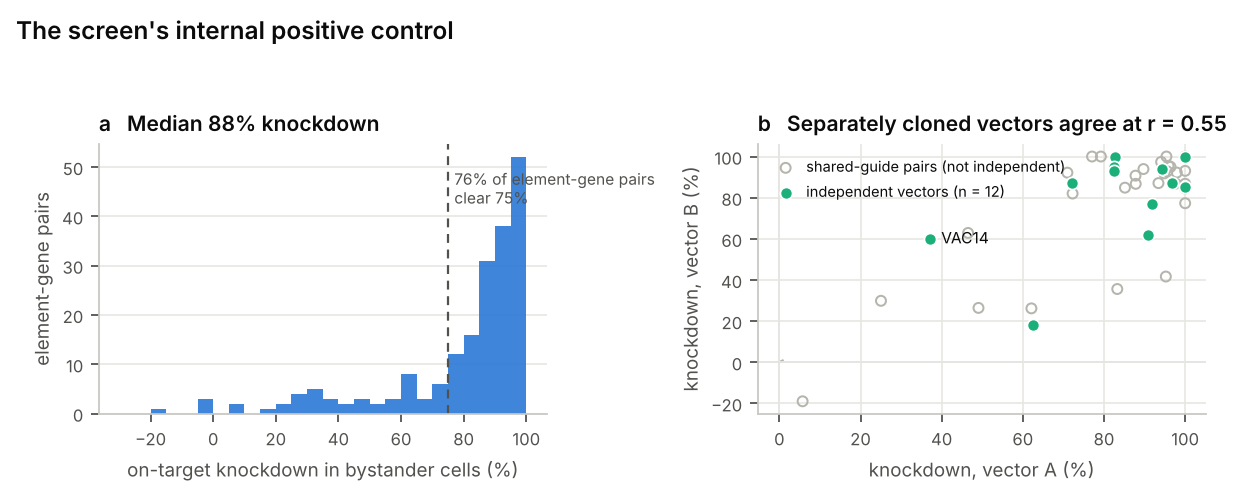

In [7]:
kd = M.table("02_knockdown.tsv")
b = kd[(kd.population == "bystander") & kd.kd_pseudobulk.notna() & (kd.n_cells >= 20)]
con = M.table("02_construct_concordance.tsv")

fig, axes = plt.subplots(1, 2, figsize=(7.6, 3.1))

ax = axes[0]
ax.hist(b.kd_pseudobulk * 100, bins=np.arange(-30, 105, 5), color=BLUE,
        linewidth=0, alpha=0.9)
style(ax)
ax.axvline(75, color=INK2, linewidth=1.0, linestyle=(0, (4, 3)))
ax.annotate(f"{(b.kd_pseudobulk > 0.75).mean()*100:.0f}% of element-gene pairs\nclear 75%",
            xy=(77, ax.get_ylim()[1] * 0.78), fontsize=7, color=INK2)
ax.set_xlabel("on-target knockdown in bystander cells (%)")
ax.set_ylabel("element-gene pairs")
ax.set_title(f"a   Median {b.kd_pseudobulk.median()*100:.0f}% knockdown", loc="left")

ax = axes[1]
indep = con[con.pair_type == "independent_vectors"]
other = con[con.pair_type != "independent_vectors"]
r = float(np.corrcoef(indep.kd_A, indep.kd_B)[0, 1])
ax.axhline(0, color=GRID, linewidth=0.8)
ax.axvline(0, color=GRID, linewidth=0.8)
ax.plot([-0.3, 1.05], [-0.3, 1.05], color=NEUTRAL, linewidth=1.0,
        linestyle=(0, (4, 3)), zorder=1)
ax.scatter(other.kd_A * 100, other.kd_B * 100, s=20, facecolor="none",
           edgecolor="#b5b4ad", linewidth=0.9, zorder=2,
           label="shared-guide pairs (not independent)")
ax.scatter(indep.kd_A * 100, indep.kd_B * 100, s=30, color=AQUA,
           edgecolor="white", linewidth=0.8, zorder=3,
           label=f"independent vectors (n = {len(indep)})")
for _, row in indep.iterrows():
    if row.target_gene in ("FURIN", "ACE2", "BRD2", "VAC14", "MEPCE", "LARP1"):
        ax.annotate(row.target_gene, (row.kd_A * 100, row.kd_B * 100),
                    textcoords="offset points", xytext=(5, -2), fontsize=7, color=INK)
style(ax, grid_axis="both")
ax.legend(frameon=False, fontsize=6.6, loc="upper left", handletextpad=0.4)
ax.set_xlabel("knockdown, vector A (%)")
ax.set_ylabel("knockdown, vector B (%)")
ax.set_title(f"b   Separately cloned vectors agree at r = {r:.2f}", loc="left")

fig.suptitle("The screen's internal positive control",
             x=0.005, ha="left", fontsize=11, fontweight="semibold")
fig.tight_layout(rect=(0, 0, 1, 0.93))
fig.savefig(M.FIGURES / "knockdown.png")
plt.show()

Left: the knockdown distribution. Right: the honest reproducibility panel, with
the shared-design pairs shown hollow so they cannot be mistaken for independent
replicates.